# Olist Delivery Delay: Arrival Forecasts and Top-10% Prioritization

**Goal:** identify more actual late orders when customer service can follow up on 10% of orders. Prediction is made at payment approval.

Keep **Recall@Top10%** as the primary measure. Compare Linear Regression, weighted XGBoost and a categorical quantile model. Rerun the original Logistic Regression as a reference on the same validation orders. EDA and preprocessing are unchanged.

## 1. Prediction and evaluation rules

1. Predict delivery days from approval; adding them to the approval date gives an arrival forecast.
2. Calculate **predicted gap = predicted delivery days − promised delivery days**. A positive gap gives a direct predicted-delay flag.
3. Rank **all** orders by the continuous gap and follow up on the highest-risk 10%.

Do not filter to positive gaps or convert gaps to 0/1 before ranking: that discards information and changes the follow-up budget. Changing a common alert threshold cannot improve a fixed top-10% ranking.

| Measure | Meaning |
|---|---|
| **Recall@Top10%** | Late orders found in the selected 10% / all actual late orders. Primary model-selection measure. |
| Precision@Top10% | Late orders found / selected orders. Measures follow-up efficiency. |
| Lift@Top10% | Selected precision / the evaluation set's late rate. A lift of 3 means three times the delay concentration of random selection. |
| Found / false alerts / missed | Counts showing the benefit and workload. |
| MAE in days | Arrival-time error. Secondary; an upper-quantile forecast is intentionally later than a typical-time forecast. |

The earlier 33% recall meant capturing about one-third of all delays, not 33% precision. Logistic Regression learns the delay event directly. Ordinary Linear Regression learns average delivery time, so replacing Logistic Regression does not automatically improve the risk ranking.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# Required: pandas, numpy, matplotlib, scikit-learn >= 1.2, xgboost, catboost.
# If needed, install missing packages in the notebook environment with %pip install xgboost catboost.
SEED = 5450
TIME = 'order_approved_at'
ACTUAL = 'order_delivered_customer_date'
PROMISED = 'order_estimated_delivery_date'
TEST_START = pd.Timestamp('2018-06-19 04:17:02')
roots = [Path('.'), Path('..')]
project = next((p for p in roots if (p / 'data/processed/olist_cleaned.csv').is_file()), None)
if project is None:
    raise FileNotFoundError('Run 01_data_cleaning.ipynb first.')
df = pd.read_csv(project / 'data/processed/olist_cleaned.csv',
                 parse_dates=[TIME, ACTUAL, PROMISED, 'order_purchase_timestamp'],
                 dtype={'customer_zip_code_prefix': 'string'})
items = pd.read_csv(project / 'data/raw/olist_order_items_dataset.csv')
# Representative seller/product: the highest-priced item, with first occurrence breaking ties.
primary = items.loc[items.groupby('order_id').price.idxmax(),
                    ['order_id', 'seller_id', 'product_id']].rename(
                        columns={'seller_id': 'primary_seller', 'product_id': 'primary_product'})
item_features = items.groupby('order_id').agg(
    max_item_price=('price', 'max'), price_std=('price', 'std'),
    max_item_freight=('freight_value', 'max'), freight_std=('freight_value', 'std'),
    distinct_products=('product_id', 'nunique'),
).fillna(0)
df = df.merge(primary, on='order_id', validate='one_to_one').merge(
    item_features, on='order_id', validate='one_to_one')
df = df.sort_values([TIME, 'order_id']).reset_index(drop=True)
df['days'] = (df[ACTUAL].dt.normalize() - df[TIME].dt.normalize()).dt.days
assert df.order_id.is_unique and (df.days >= 0).all()
assert np.array_equal((df.days > df.promised_delivery_days).astype(int), df.late_delivery)
assert (df.promised_delivery_days == (
    df[PROMISED].dt.normalize() - df[TIME].dt.normalize()).dt.days).all()
INPUTS = [
    'customer_state', 'customer_city', 'customer_zip_code_prefix',
    'promised_delivery_days', 'total_freight', 'total_price', 'approval_duration_hours',
    'item_count', 'seller_count', 'purchase_month', 'purchase_weekday', 'purchase_hour',
    'order_purchase_timestamp', TIME, 'primary_seller', 'primary_product',
    'max_item_price', 'price_std', 'max_item_freight', 'freight_std', 'distinct_products',
]
assert not set(INPUTS) & {ACTUAL, PROMISED, 'order_delivered_carrier_date',
                          'late_delivery', 'days', 'order_id', 'customer_id'}
assert not df[INPUTS].isna().any().any()
print(f'Orders: {len(df):,}. Test predictions are not made in this notebook.')

Orders: 95,104. Test predictions are not made in this notebook.


## 2. Shared validation orders and model selection

Preserve the original approval-time boundaries: approximately 70% before validation, 15% validation, 15% reserved test. Split validation into an earlier tuning segment and a later check segment.

Training uses earlier approvals with already-observed deliveries. Compare 30- and 45-day maturity gaps for XGBoost, choosing its gap and late-order weight on the earlier segment. Reference and linear models use 30 days. Thus evaluation orders are identical, while a selected training-window setting can differ.

Select settings using **earlier-segment Recall@Top10% only**. Report the later segment separately. The combined validation table includes tuning orders and is a development summary, not an independent test result. Later outcomes are assessed retrospectively; earlier-segment delay labels are knowable before the reserved test begins.

All preprocessing references come from training data. Carrier handover and actual delivery never enter model inputs. The reserved test remains unscored.

In [2]:
VAL_START = df[TIME].iloc[int(0.70 * len(df))]
assert df[TIME].iloc[int(0.85 * len(df))] == TEST_START
validation = df.loc[(df[TIME] >= VAL_START) & (df[TIME] < TEST_START)].copy()
CHECK_START = validation[TIME].iloc[len(validation) // 2]
tuning_mask = (validation[TIME] < CHECK_START).to_numpy()
check_mask = ~tuning_mask
assert ((validation.loc[tuning_mask, ACTUAL] < TEST_START) |
        (validation.loc[tuning_mask, PROMISED] + pd.Timedelta(days=1) <= TEST_START)).all()


def training_data(gap):
    eligible = df.loc[df[TIME] < VAL_START - pd.Timedelta(days=gap)]
    train = eligible.loc[eligible[ACTUAL] < VAL_START].copy()
    assert train[TIME].max() < VAL_START - pd.Timedelta(days=gap)
    assert train[ACTUAL].max() < VAL_START
    assert train[TIME].is_monotonic_increasing
    return train, len(eligible) - len(train)


train30, excluded30 = training_data(30)
train45, excluded45 = training_data(45)
display(pd.DataFrame([
    {'Part': 'Train / 30-day gap', 'Orders': len(train30), 'First approval': train30[TIME].min(),
     'Last approval': train30[TIME].max()},
    {'Part': 'Train / 45-day gap', 'Orders': len(train45), 'First approval': train45[TIME].min(),
     'Last approval': train45[TIME].max()},
    *[{'Part': name, 'Orders': int(mask.sum()),
       'First approval': validation.loc[mask, TIME].min(),
       'Last approval': validation.loc[mask, TIME].max()}
      for name, mask in [('Tuning', tuning_mask), ('Later check', check_mask)]],
]))
print(f'Older unresolved training orders excluded: {excluded30} (30d), {excluded45} (45d).')
print(f'Combined validation: {len(validation):,} orders, {validation.late_delivery.sum():,} actual delays.')

,Part,Orders,First approval,Last approval
0,Train / 30-day gap,59522,2016-09-15 12:16:38,2018-03-13 05:40:32
1,Train / 45-day gap,56082,2016-09-15 12:16:38,2018-02-26 07:28:23
2,Tuning,7133,2018-04-12 07:51:25,2018-05-12 20:10:23
3,Later check,7133,2018-05-12 20:10:25,2018-06-19 04:16:58


Older unresolved training orders excluded: 408 (30d), 95 (45d).
Combined validation: 14,266 orders, 635 actual delays.


## 3. EDA-driven feature engineering

| EDA finding | Feature choice |
|---|---|
| Geography changes delay rates; promise length mixes destination risk and buffer | Customer state, promised days and promise relative to the training state's median |
| Freight overlaps geography | Use log freight with state; linear models also get state × freight and state × relative-promise terms |
| Approval, freight and price are skewed | `log1p`; standardize numeric inputs for linear models |
| Seller/item counts show meaningful group differences | Retain both counts |
| Risk changes over calendar time | Calendar trend and cyclic month, weekday and hour |

The categorical extension adds ZIP prefixes, customer city, representative seller/product identifiers and item-level price/freight summaries. Seller and product IDs repeat across orders and can describe recurring fulfillment patterns; they are not unique order identifiers. **Product ID is not a product-category field.** These extensions are tested rather than assumed to help.

Raw order items are aggregated only within the current order. No delivery outcomes are used to build these additional inputs.

In [3]:
class EDAFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, expanded=False, interactions=False):
        self.expanded = expanded
        self.interactions = interactions

    def fit(self, X, y=None):
        self.promise_by_state_ = X.groupby('customer_state').promised_delivery_days.median()
        self.promise_global_ = X.promised_delivery_days.median()
        self.freight_by_state_ = X.groupby('customer_state').total_freight.median()
        self.freight_global_ = X.total_freight.median()
        self.origin_ = X.order_purchase_timestamp.min().normalize()
        self.states_ = sorted(X.customer_state.unique())
        return self

    def transform(self, X):
        out = X[['customer_state', 'promised_delivery_days', 'item_count', 'seller_count']].copy()
        reference = X.customer_state.map(self.promise_by_state_).fillna(self.promise_global_)
        out['relative_promise_days'] = X.promised_delivery_days - reference
        for col in ['total_price', 'total_freight', 'approval_duration_hours']:
            out['log_' + col] = np.log1p(X[col])
        for col, period in [('purchase_month', 12), ('purchase_weekday', 7), ('purchase_hour', 24)]:
            angle = 2 * np.pi * X[col] / period
            out[col + '_sin'] = np.sin(angle)
            out[col + '_cos'] = np.cos(angle)
        out['calendar_trend_days'] = (X.order_purchase_timestamp - self.origin_).dt.total_seconds() / 86400
        if self.expanded:
            out['zip2'] = X.customer_zip_code_prefix.str.zfill(5).str[:2].astype(str)
            out['multi_seller'] = (X.seller_count > 1).astype(int)
            out['multi_item'] = (X.item_count > 1).astype(int)
            out['log_freight_per_item'] = np.log1p(X.total_freight / X.item_count)
            out['log_price_per_item'] = np.log1p(X.total_price / X.item_count)
            freight_reference = X.customer_state.map(self.freight_by_state_).fillna(self.freight_global_)
            out['relative_log_freight'] = np.log1p(X.total_freight) - np.log1p(freight_reference)
            out['approval_window_fraction'] = X.approval_duration_hours / (24 * X.promised_delivery_days.clip(lower=1))
        if self.interactions:
            for state in self.states_[1:]:
                indicator = (X.customer_state == state).astype(float)
                out['promise_x_' + state] = out.relative_promise_days * indicator
                out['freight_x_' + state] = out.log_total_freight * indicator
        assert np.isfinite(out.select_dtypes(include=np.number).to_numpy()).all()
        return out


def make_pipeline_model(estimator, linear=False):
    preprocess = ColumnTransformer([
        ('numeric', StandardScaler() if linear else 'passthrough',
         make_column_selector(dtype_include=np.number)),
        ('category', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         make_column_selector(dtype_include=['object', 'string'])),
    ])
    return Pipeline([('features', EDAFeatures(interactions=linear)),
                     ('preprocess', preprocess), ('model', estimator)])


def top10_metrics(actual_late, scores):
    y = np.asarray(actual_late, dtype=int)
    s = np.asarray(scores, dtype=float)
    assert len(y) == len(s) and np.isfinite(s).all() and y.sum() > 0
    k = int(np.ceil(0.10 * len(y)))
    tie_breaker = np.random.default_rng(SEED).random(len(y))
    top = np.lexsort((tie_breaker, -s))[:k]
    found = int(y[top].sum())
    return {'Selected': k, 'Found': found, 'False alerts': k - found,
            'Missed': int(y.sum()) - found, 'Recall@Top10%': found / y.sum(),
            'Precision@Top10%': found / k, 'Lift@Top10%': (found / k) / y.mean()}


X_val = validation[INPUTS]
y_val = validation.late_delivery.to_numpy()
promise_val = validation.promised_delivery_days.to_numpy()
models, forecasts, scores = {}, {}, {}

## 4. Reference and baseline

**Logistic reference:** rerun the original numeric features and state encoding on the current training snapshot. This provides a matched comparison with the earlier approximately 33% recall.

**Linear Regression baseline:** use EDA features to predict actual delivery days. Rank by the predicted gap. The objective is timing error, so a good MAE need not produce the best delay ranking.

In [4]:
legacy_numeric = ['purchase_month', 'purchase_weekday', 'purchase_hour',
                  'approval_duration_hours', 'promised_delivery_days',
                  'item_count', 'total_price', 'total_freight', 'seller_count']
legacy_preprocess = ColumnTransformer([
    ('numeric', StandardScaler(), legacy_numeric),
    ('state', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['customer_state']),
])
logistic = Pipeline([
    ('preprocess', legacy_preprocess),
    ('model', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=SEED)),
])
logistic.fit(train30[INPUTS], train30.late_delivery)
models['Logistic reference'] = logistic
scores['Logistic reference'] = logistic.predict_proba(X_val)[:, 1]

linear = make_pipeline_model(LinearRegression(), linear=True)
linear.fit(train30[INPUTS], train30.days)
models['Linear Regression'] = linear
forecasts['Linear Regression'] = np.maximum(linear.predict(X_val), 0)
scores['Linear Regression'] = forecasts['Linear Regression'] - promise_val

## 5. Model 1: weighted XGBoost arrival forecast

**Motivation:** average-time regression gives most influence to common on-time orders. Give observed late training orders additional weight, then still predict delivery days and rank the predicted gap.

Compare two maturity gaps and two weights. Choose by earlier-segment Recall@Top10%, not MAE. A weighted forecast is risk-oriented and can overestimate typical delivery time; report that trade-off rather than calling it an unbiased average ETA.

In [5]:
xgb_candidates, xgb_rows = [], []
for gap in [30, 45]:
    train, _ = training_data(gap)
    for late_weight in [1, 5]:
        estimator = XGBRegressor(
            objective='reg:squarederror', n_estimators=300, max_depth=3,
            learning_rate=.05, min_child_weight=20, subsample=.8,
            colsample_bytree=.9, reg_lambda=20, n_jobs=2, tree_method='hist', random_state=SEED,
        )
        model = make_pipeline_model(estimator)
        weights = np.where(train.late_delivery.to_numpy() == 1, late_weight, 1.)
        model.fit(train[INPUTS], train.days, model__sample_weight=weights)
        days = np.maximum(model.predict(X_val), 0)
        gap_score = days - promise_val
        result = top10_metrics(y_val[tuning_mask], gap_score[tuning_mask])
        xgb_candidates.append((model, days, gap_score))
        xgb_rows.append({'Maturity gap': gap, 'Late weight': late_weight,
                         'Tuning recall': result['Recall@Top10%']})
xgb_tuning = pd.DataFrame(xgb_rows)
best_xgb = int(xgb_tuning['Tuning recall'].to_numpy().argmax())
models['Weighted XGBoost'], forecasts['Weighted XGBoost'], scores['Weighted XGBoost'] = xgb_candidates[best_xgb]
display(xgb_tuning.round(4))
print('Selected:', xgb_tuning.iloc[best_xgb].to_dict())

,Maturity gap,Late weight,Tuning recall
0,30,1,0.2082
1,30,5,0.2397
2,45,1,0.2397
3,45,5,0.2902


Selected: {'Maturity gap': 45.0, 'Late weight': 5.0, 'Tuning recall': 0.2902208201892745}


## 6. Model 2: categorical upper-arrival forecast

**Motivation:** seller and product identities may carry information lost by keeping only seller count. CatBoost handles these repeated categorical inputs. Compare typical-time regression, extra weight on late orders, and 80th/90th-percentile arrival forecasts.

A quantile forecast describes a slower delivery scenario. It is used as a warning score, not presented as the average expected arrival date or a validated guarantee. Choose its objective on earlier-segment Recall@Top10%. No later-segment labels select settings.

Implementation: [CatBoost categorical features](https://catboost.ai/docs/en/features/categorical-features), [regression objectives](https://catboost.ai/docs/en/concepts/loss-functions-regression).

In [6]:
categorical_features = EDAFeatures(expanded=True).fit(train30[INPUTS])


def categorical_frame(part):
    out = categorical_features.transform(part[INPUTS])
    for col in ['primary_seller', 'primary_product', 'customer_city']:
        out[col] = part[col].astype(str)
    out['zip3'] = part.customer_zip_code_prefix.str.zfill(5).str[:3].astype(str)
    for col in ['max_item_price', 'price_std', 'max_item_freight', 'freight_std']:
        out['log_' + col] = np.log1p(part[col])
    out['distinct_products'] = part.distinct_products
    return out


cat_train, cat_val = categorical_frame(train30), categorical_frame(validation)
cat_columns = cat_train.select_dtypes(include=['object', 'string']).columns.tolist()
cat_candidates, cat_rows = [], []
for name, loss, late_weight in [
    ('Typical time', 'RMSE', 1), ('Weighted time', 'RMSE', 5),
    ('Upper 80%', 'Quantile:alpha=0.8', 1), ('Upper 90%', 'Quantile:alpha=0.9', 1),
]:
    model = CatBoostRegressor(
        iterations=500, depth=6, learning_rate=.05, l2_leaf_reg=10,
        cat_features=cat_columns, has_time=True, thread_count=2,
        random_seed=SEED, verbose=False, allow_writing_files=False, loss_function=loss,
    )
    model.fit(cat_train, train30.days,
              sample_weight=np.where(train30.late_delivery.to_numpy() == 1, late_weight, 1.))
    days = np.maximum(model.predict(cat_val), 0)
    gap_score = days - promise_val
    result = top10_metrics(y_val[tuning_mask], gap_score[tuning_mask])
    cat_candidates.append((model, days, gap_score))
    cat_rows.append({'Objective': name, 'Tuning recall': result['Recall@Top10%']})
cat_tuning = pd.DataFrame(cat_rows)
best_cat = int(cat_tuning['Tuning recall'].to_numpy().argmax())
models['Categorical arrival model'], forecasts['Categorical arrival model'], scores['Categorical arrival model'] = cat_candidates[best_cat]
display(cat_tuning.round(4))
print('Selected:', cat_tuning.iloc[best_cat].to_dict())

,Objective,Tuning recall
0,Typical time,0.2492
1,Weighted time,0.2744
2,Upper 80%,0.2776
3,Upper 90%,0.2145


Selected: {'Objective': 'Upper 80%', 'Tuning recall': 0.277602523659306}


## 7. Validation results: fixed follow-up workload

Report the later check first, then the combined validation development summary. Every method selects the same number of orders in its evaluation set. Random selection is an analytical expectation, not another fitted model.

Neither segment is the reserved test. The project has explored validation repeatedly, so these results still need confirmation on that reserved test. Do not describe a gain in one segment as an improvement in every period.

Later check: 7,133 orders, 318 actual delays.


,Selected,Found,False alerts,Missed,Recall@Top10%,Precision@Top10%,Lift@Top10%
Model,,,,,,,
Logistic reference,714,109,605,209,0.3428,0.1527,3.4243
Linear Regression,714,100,614,218,0.3145,0.1401,3.1416
Weighted XGBoost,714,98,616,220,0.3082,0.1373,3.0787
Categorical arrival model,714,130,584,188,0.4088,0.1821,4.0840


Combined validation (includes tuning): 14,266 orders, 635 actual delays.


,Selected,Found,False alerts,Missed,Recall@Top10%,Precision@Top10%,Lift@Top10%
Model,,,,,,,
Logistic reference,1427,208,1219,427,0.3276,0.1458,3.2747
Linear Regression,1427,167,1260,468,0.2630,0.1170,2.6292
Weighted XGBoost,1427,188,1239,447,0.2961,0.1317,2.9598
Categorical arrival model,1427,207,1220,428,0.3260,0.1451,3.2589


Random follow-up expectation on later check: 31.8 delays found; recall 10.01%.


,Model,Forecast type,MAE days
0,Linear Regression,Typical time,6.749
1,Weighted XGBoost,Risk-oriented time,9.709
2,Categorical arrival model,Risk-oriented time,9.931


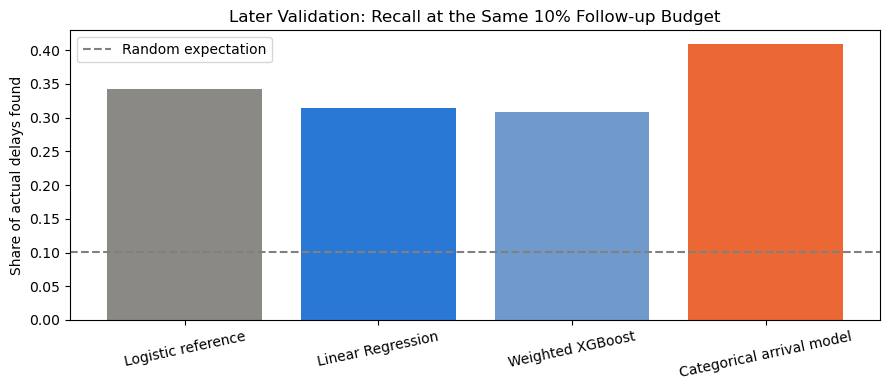

In [7]:
MAIN = ['Logistic reference', 'Linear Regression', 'Weighted XGBoost', 'Categorical arrival model']


def comparison(mask):
    return pd.DataFrame([
        {'Model': name, **top10_metrics(y_val[mask], scores[name][mask])}
        for name in MAIN
    ]).set_index('Model')


check_results = comparison(check_mask)
combined_results = comparison(np.ones(len(validation), dtype=bool))
print(f'Later check: {check_mask.sum():,} orders, {y_val[check_mask].sum():,} actual delays.')
display(check_results.round(4))
print(f'Combined validation (includes tuning): {len(validation):,} orders, {y_val.sum():,} actual delays.')
display(combined_results.round(4))

k = int(np.ceil(.1 * check_mask.sum()))
print(f'Random follow-up expectation on later check: {k * y_val[check_mask].mean():.1f} delays found; '
      f'recall {k / check_mask.sum():.2%}.')
error_rows = [
    {'Model': name, 'Forecast type': 'Typical time' if name == 'Linear Regression' else 'Risk-oriented time',
     'MAE days': mean_absolute_error(validation.days, days)}
    for name, days in forecasts.items()
]
display(pd.DataFrame(error_rows).round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(check_results.index, check_results['Recall@Top10%'], color=['#8a8984', '#2a78d6', '#709acc', '#eb6834'])
ax.axhline(k / check_mask.sum(), color='gray', linestyle='--', label='Random expectation')
ax.set_ylabel('Share of actual delays found')
ax.set_title('Later Validation: Recall at the Same 10% Follow-up Budget')
ax.tick_params(axis='x', rotation=12)
ax.legend()
fig.tight_layout()
plt.show()

## 8. Check what the categorical extension adds

Fit the selected categorical objective again using only core EDA inputs. Compare it with the expanded input set at the same settings. This separates the feature extension from the quantile objective. It is an interpretation check and does not trigger further tuning.

In [8]:
core_cat_features = EDAFeatures().fit(train30[INPUTS])
core_cat_train = core_cat_features.transform(train30[INPUTS])
core_cat_val = core_cat_features.transform(validation[INPUTS])
selected_loss = cat_candidates[best_cat][0].get_param('loss_function')
selected_weight = 5 if cat_tuning.iloc[best_cat]['Objective'] == 'Weighted time' else 1
core_cat_model = CatBoostRegressor(
    iterations=500, depth=6, learning_rate=.05, l2_leaf_reg=10,
    cat_features=['customer_state'], has_time=True, thread_count=2,
    random_seed=SEED, verbose=False, allow_writing_files=False, loss_function=selected_loss,
)
core_cat_model.fit(core_cat_train, train30.days,
                   sample_weight=np.where(train30.late_delivery.to_numpy() == 1, selected_weight, 1.))
core_days = np.maximum(core_cat_model.predict(core_cat_val), 0)
core_score = core_days - promise_val
ablation_rows = []
for name, score in [('Core inputs', core_score), ('Expanded inputs', scores['Categorical arrival model'])]:
    ablation_rows.append({'Features': name,
        'Tuning recall': top10_metrics(y_val[tuning_mask], score[tuning_mask])['Recall@Top10%'],
        'Later recall': top10_metrics(y_val[check_mask], score[check_mask])['Recall@Top10%'],
        'Combined recall': top10_metrics(y_val, score)['Recall@Top10%']})
display(pd.DataFrame(ablation_rows).round(4))

# A few rows make the forecast -> direct flag -> continuous rank distinction concrete.
example_days = forecasts['Categorical arrival model']
examples = validation[['order_id', TIME, PROMISED]].head(6).copy()
examples['forecast_days'] = example_days[:6].round(2)
examples['forecast_arrival_date'] = examples[TIME].dt.normalize() + pd.to_timedelta(np.ceil(example_days[:6]), unit='D')
examples['predicted_gap_days'] = (example_days - promise_val)[:6].round(2)
examples['direct_predicted_late'] = ((example_days - promise_val) > 0)[:6]
examples['actual_late'] = y_val[:6]
display(examples)
print('Displayed dates round fractional days upward; ranking uses the unrounded continuous gap.')

,Features,Tuning recall,Later recall,Combined recall
0,Core inputs,0.2050,0.3868,0.274
1,Expanded inputs,0.2776,0.4088,0.326


,order_id,order_approved_at,order_estimated_delivery_date,forecast_days,forecast_arrival_date,predicted_gap_days,direct_predicted_late,actual_late
66572,305521e597cd32f946da81d3649d31b9,2018-04-12 07:51:25,2018-04-26,11.63,2018-04-24,-2.37,False,0
66573,46c99067d2014deb825b963f5acc76da,2018-04-12 08:10:04,2018-05-14,25.15,2018-05-08,-6.85,False,0
66574,cf6aa522d7b94b77f266075aa45f99af,2018-04-12 08:15:12,2018-04-27,19.89,2018-05-02,4.89,True,0
66575,fc893e13a220f3fb9b2108b582e773a0,2018-04-12 08:32:18,2018-04-24,10.07,2018-04-23,-1.93,False,0
66576,e3b8f30edc738fdf0897de9bf8b49d56,2018-04-12 08:32:19,2018-05-04,21.58,2018-05-04,-0.42,False,0
66577,c1e4bdeeda1ce8c91f4c71b977fca35f,2018-04-12 08:32:29,2018-04-26,12.80,2018-04-25,-1.20,False,0


Displayed dates round fractional days upward; ranking uses the unrounded continuous gap.


## 9. Decision tree interpretation and conclusions

Keep a shallow regression tree as an explanation tool for typical delivery days. It does not replace the ranking evaluation and does not establish causal effects. Its split importance can favor variables with more possible splits; correlated factors can share importance.

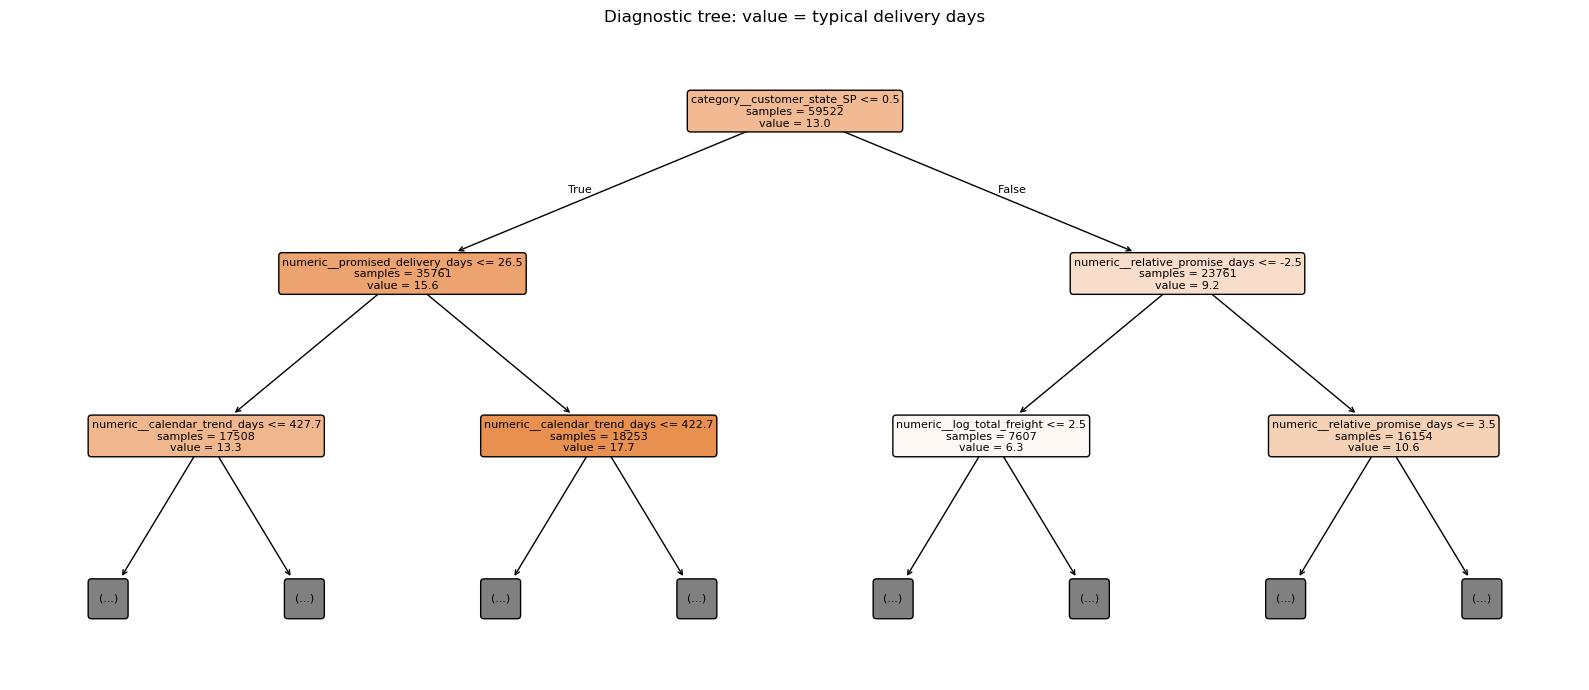

Later-segment comparison:
Logistic reference: 109 delays found, recall 34.3%, precision 15.3%, lift 3.42x.
Linear Regression: 100 delays found, recall 31.4%, precision 14.0%, lift 3.14x.
Weighted XGBoost: 98 delays found, recall 30.8%, precision 13.7%, lift 3.08x.
Categorical arrival model: 130 delays found, recall 40.9%, precision 18.2%, lift 4.08x.


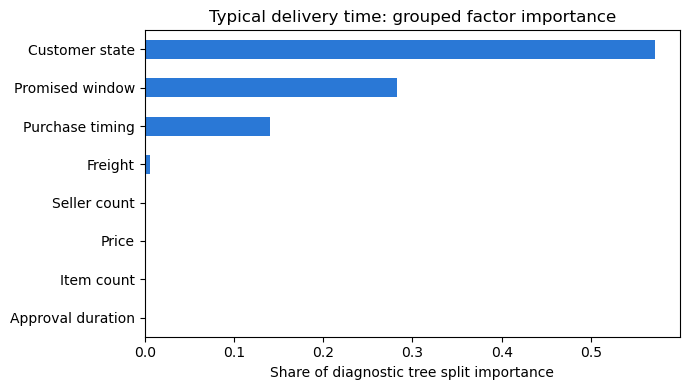

In [9]:
diagnostic = make_pipeline_model(DecisionTreeRegressor(
    max_depth=3, min_samples_leaf=200, random_state=SEED))
diagnostic.fit(train30[INPUTS], train30.days)
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(diagnostic.named_steps['model'], max_depth=2,
          feature_names=diagnostic.named_steps['preprocess'].get_feature_names_out(),
          filled=True, rounded=True, impurity=False, precision=1, fontsize=8, ax=ax)
ax.set_title('Diagnostic tree: value = typical delivery days')
fig.tight_layout()
plt.show()

print('Later-segment comparison:')
for name in MAIN:
    r = check_results.loc[name]
    print(f"{name}: {int(r['Found'])} delays found, recall {r['Recall@Top10%']:.1%}, "
          f"precision {r['Precision@Top10%']:.1%}, lift {r['Lift@Top10%']:.2f}x.")

feature_names = diagnostic.named_steps['preprocess'].get_feature_names_out()
def factor(name):
    if 'customer_state_' in name:
        return 'Customer state'
    if 'promise' in name:
        return 'Promised window'
    if 'freight' in name:
        return 'Freight'
    if 'price' in name:
        return 'Price'
    if 'approval' in name:
        return 'Approval duration'
    if 'item_count' in name:
        return 'Item count'
    if 'seller_count' in name:
        return 'Seller count'
    return 'Purchase timing'
importance = pd.Series(diagnostic.named_steps['model'].feature_importances_,
                       index=[factor(name) for name in feature_names]).groupby(level=0).sum()
fig, ax = plt.subplots(figsize=(7, 4))
importance.sort_values().plot.barh(ax=ax, color='#2a78d6')
ax.set_xlabel('Share of diagnostic tree split importance')
ax.set_title('Typical delivery time: grouped factor importance')
fig.tight_layout()
plt.show()


### What this supports

- Ordinary arrival-time regression is not automatically a better delay ranker than Logistic Regression. The matched reference explains why the earlier approximately 33% recall was useful.
- Choosing by Recall@Top10% keeps model selection aligned with customer-service capacity. Precision, order counts and lift explain its cost and benefit; accuracy is not used to select models.
- Weighting late examples and forecasting a slower arrival scenario can improve ranking relative to the linear arrival baseline, with higher point-time error. These are risk-oriented forecasts, not claimed improvements in average ETA accuracy.
- The categorical model's later-segment performance is promising, but the combined development result does not consistently exceed the Logistic reference. Do not claim an overall or final-test improvement from a single favorable segment.
- Exploratory history encodings, multi-quantile interpolation and ETA-assisted stacking did not produce a stable overall gain in this development run, so they are not part of the main pipeline.

Freeze these feature definitions, selected settings and the 10% follow-up rule before final test evaluation. The fitted objects above remain validation-stage models; any final refit must use the same documented outcome-availability rules. No test predictions are made here.

The dataset covers eventually delivered orders; shipment-based filtering and remaining training selection can affect generalization. Associations are not causal effects. EDA already examined the full dataset, and repeated validation exploration means the reserved test is needed for a final performance claim.